### Section 1. 

In [2]:
# download 
!wget https://opendata.rijdendetreinen.nl/public/tariff-distances/tariff-distances-2022-01.csv -O data/distances-2022.csv 



7[Files: 0  Bytes: 0  [0 B/s] Re]87[https://opendata.rijdendetrein]87Saving 'data/distances-2022.csv'
87data/distances-2022. 100% [=============================>]  569.85K    --.-KB/s87HTTP response 200  [https://opendata.rijdendetreinen.nl/public/tariff-distances/tariff-distances-2022-01.csv]
87data/distances-2022. 100% [=============================>]  569.85K    --.-KB/s87[Files: 1  Bytes: 569.85K [1.01]8

In [3]:
# download railway stations in 2023
!wget https://opendata.rijdendetreinen.nl/public/stations/stations-2023-09.csv -O data/stations-2023.csv



7[Files: 0  Bytes: 0  [0 B/s] Re]87[https://opendata.rijdendetrein]87Saving 'data/stations-2023.csv'
87data/stations-2023.c 100% [=============================>]   63.48K    --.-KB/s87HTTP response 200  [https://opendata.rijdendetreinen.nl/public/stations/stations-2023-09.csv]
87data/stations-2023.c 100% [=============================>]   63.48K    --.-KB/s87[Files: 1  Bytes: 63.48K [145.6]8

In [4]:
# download train disruptions between 2011 and 2023
!wget -P data/ https://opendata.rijdendetreinen.nl/public/disruptions/disruptions-{2011..2023}.csv







7[Files: 0  Bytes: 0  [0 B/s] Re]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87Saving 'data//disruptions-2023.csv'
87Saving 'data//disruptions-2014.csv'
87disruptions-2023.csv   3% [>                             ]   54.87K    --.-KB/s87Saving 'data//disruptions-2012.csv'
87disruptions-2014.csv   2% [>                             ]   10.67K    --.-KB/s87Saving 'data//disruptions-2015.csv'
87disruptions-2014.csv   4% [>                             ]   21.36K    5.21MB/s87disruptions-2012.csv   3% [>                             ]   17.35K    --.-KB/s

In [5]:
# download train services between 2019 and 2025
!wget -P data/ https://opendata.rijdendetreinen.nl/public/services/services-{2019..2025}.csv.gz







7[Files: 0  Bytes: 0  [0 B/s] Re]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87[https://opendata.rijdendetrein]87Saving 'data//services-2024.csv.gz'
87Saving 'data//services-2019.csv.gz'
87services-2024.csv.gz   0% [>                             ]   50.74K    --.-KB/s87Saving 'data//services-2020.csv.gz'
87services-2024.csv.gz   0% [>                             ]   58.99K    1.34MB/s87services-2019.csv.gz   0% [>                             ]   48.06K    --.-KB/s87Saving 'data//services-2022.csv.gz'
87services-2020.csv.gz   0% [>                             ]   59.31K    --.-KB/s87services-2019.csv.gz   0% [>                             ]   54.87K  377.98KB/s87Saving 'data//services-2023.csv.gz'
87services-2022.csv.gz   0% [>                             ]    4.00K    --.-KB/s87Saving

In [6]:
# unzip train services
!gzip -f -d data/services-*.csv.gz

### Section 2.

In [1]:
import duckdb

db = duckdb.connect('data/trains_data.db')

In [9]:
db.sql("""
CREATE TABLE IF NOT EXISTS stations AS
FROM "data/stations-2023.csv"
""")

In [2]:
db.sql("DESCRIBE stations")

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ id          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ code        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ uic         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ name_short  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_medium │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ name_long   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ slug        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ country     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ type        │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lat     │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ geo_lng     │ DOUB

### Section 3.

In [17]:
db.sql("""
CREATE TABLE IF NOT EXISTS distances AS
FROM read_csv("data/distances-2022.csv", nullstr='XXX')
""")

In [3]:
db.sql("DESCRIBE distances")

┌─────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│ column_name │ column_type │  null   │   key   │ default │  extra  │
│   varchar   │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ Station     │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ AC          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AH          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AHP         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AHPR        │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AHZ         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AKL         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ AKM         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ ALM         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ ALMB        │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│  ·          │   · 

In [19]:
db.sql("""
CREATE TABLE IF NOT EXISTS distances_long AS
    UNPIVOT distances
    ON COLUMNS (* EXCLUDE station)
    INTO NAME other_station VALUE distance;
""")

In [7]:
db.sql("DESCRIBE distances_long")

┌───────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│  column_name  │ column_type │  null   │   key   │ default │  extra  │
│    varchar    │   varchar   │ varchar │ varchar │ varchar │ varchar │
├───────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ Station       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ other_station │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ distance      │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
└───────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

### Section 4.

In terminal:
```
docker stop [previous_postgres_container_id]
docker compose up -d
```

In [ ]:
db.sql("""INSTALL postgres; LOAD postgres;""")
conn_string = "host=localhost user=postgres password=postgres dbname=postgres"

In [3]:
db.sql("SHOW ALL TABLES")

┌─────────────┬─────────┬────────────────┬──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────

In [4]:
db.sql(f"""
ATTACH IF NOT EXISTS '{conn_string}' AS postgres_db (TYPE postgres);
""")

In [29]:
db.sql("""
CREATE TABLE IF NOT EXISTS postgres_db.disruptions AS
FROM read_csv('data/disruptions-*.csv', union_by_name=true)
""")

In [5]:
db.sql("DESCRIBE postgres_db.disruptions")

┌──────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│     column_name      │ column_type │  null   │   key   │ default │  extra  │
│       varchar        │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ rdt_id               │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ ns_lines             │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_lines            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_lines_id         │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_station_names    │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ rdt_station_codes    │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ cause_nl             │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ cause_en             │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ statistical_cause_nl │ VARCHAR     │ YES     │ NUL

### Section 5.

In [9]:
# duckdb.sql("""
# COPY (SELECT * FROM "data/services-*.csv") TO "data/services.parquet" (FORMAT parquet, COMPRESSION zstd);
# """) # commented out to avoid recopying the file

In [32]:
db.sql("""
CREATE TABLE IF NOT EXISTS services AS
FROM "data/services.parquet"
""")
db.sql("DESCRIBE services")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌──────────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│         column_name          │ column_type │  null   │   key   │ default │  extra  │
│           varchar            │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ Service:RDT-ID               │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Date                 │ DATE        │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Type                 │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Company              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Train number         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Completely cancelled │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Partly cancelled     │ BOOLEAN     │ YES     │ NULL    │ NULL    │ NULL    │
│ Service:Maximum delay        │ BIGINT    

In [11]:
db.sql("""
SELECT * FROM services
LIMIT 10
""")

┌────────────────┬──────────────┬──────────────┬─────────────────┬──────────────────────┬──────────────────────────────┬──────────────────────────┬───────────────────────┬─────────────┬───────────────────┬─────────────────────────┬─────────────────────┬────────────────────┬────────────────────────┬─────────────────────┬──────────────────────┬──────────────────────────┬──────────────────────┬───────────────────────┬──────────────────────┐
│ Service:RDT-ID │ Service:Date │ Service:Type │ Service:Company │ Service:Train number │ Service:Completely cancelled │ Service:Partly cancelled │ Service:Maximum delay │ Stop:RDT-ID │ Stop:Station code │    Stop:Station name    │  Stop:Arrival time  │ Stop:Arrival delay │ Stop:Arrival cancelled │ Stop:Departure time │ Stop:Departure delay │ Stop:Departure cancelled │ Stop:Platform change │ Stop:Planned platform │ Stop:Actual platform │
│     int64      │     date     │   varchar    │     varchar     │        int64         │           boolean         

### Section 7.

In [27]:
# I. How many trains departed from Amsterdam Central station overall?
db.sql("""
SELECT COUNT(*) FROM services
WHERE "Stop:Station name" = 'Amsterdam Centraal'
AND "Stop:Departure time" IS NOT NULL
""")

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│      1940873 │
└──────────────┘

In [30]:
# II.  Calculate the average arrival delay of different service types (Service:Type).
#      Order results descending by average delay.

db.sql("""
SELECT "Service:Type", ROUND(AVG(COALESCE("Stop:Arrival delay", 0)), 2) AS avg_delay
FROM services
GROUP BY "Service:Type"
ORDER BY avg_delay DESC
""")

┌──────────────────────┬───────────┐
│     Service:Type     │ avg_delay │
│       varchar        │  double   │
├──────────────────────┼───────────┤
│ Alpen Express        │     21.96 │
│ European Sleeper     │      11.6 │
│ Krokus Express       │     11.38 │
│ Nightjet             │      8.06 │
│ ICE                  │      7.09 │
│ Eurostar             │       5.7 │
│ ICE International    │      4.79 │
│ Thalys               │      4.37 │
│ Int. Trein           │      3.74 │
│ Nachttrein           │      3.33 │
│     ·                │        ·  │
│     ·                │        ·  │
│     ·                │        ·  │
│ OV-bus ipv trein     │       0.0 │
│ Belbus ipv trein     │       0.0 │
│ Niet instappen       │       0.0 │
│ Stopbus i.p.v. trein │       0.0 │
│ Metro                │       0.0 │
│ Bus                  │       0.0 │
│ Metro ipv trein      │       0.0 │
│ Taxibus ipv trein    │       0.0 │
│ Tram i.p.v. trein    │       0.0 │
│ Belbus               │       0.0 │
├

In [31]:
# III. What was the most common disruption cause in different years? MODE function may be useful

db.sql("""
SELECT EXTRACT(YEAR FROM "start_time") as year, MODE(cause_en) as cause_en
FROM postgres_db.disruptions
GROUP BY year
ORDER BY year
""")


┌───────┬───────────────────┐
│ year  │     cause_en      │
│ int64 │      varchar      │
├───────┼───────────────────┤
│  2011 │ broken down train │
│  2012 │ points failure    │
│  2013 │ points failure    │
│  2014 │ broken down train │
│  2015 │ broken down train │
│  2016 │ broken down train │
│  2017 │ broken down train │
│  2018 │ broken down train │
│  2019 │ broken down train │
│  2020 │ broken down train │
│  2021 │ broken down train │
│  2022 │ broken down train │
│  2023 │ broken down train │
├───────┴───────────────────┤
│ 13 rows         2 columns │
└───────────────────────────┘

In [33]:
# IV. How many trains started their overall service in any Amsterdam station?

db.sql("""
SELECT COUNT (*)
FROM services
WHERE "Stop:Station name" LIKE '%Amsterdam%'
AND "Stop:Arrival time" IS NULL
""")


┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│      1289250 │
└──────────────┘

In [36]:
# V. What fraction of services was run to final destinations outside the Netherlands?

db.sql("""
SELECT COUNT (*) FILTER (WHERE country <> 'NL') / COUNT (*) as fraction
FROM services
JOIN stations ON "Stop:Station code" = code
WHERE "Stop:Departure time" IS NULL
""")

┌─────────────────────┐
│      fraction       │
│       double        │
├─────────────────────┤
│ 0.03803741997174202 │
└─────────────────────┘

In [37]:
# VI. What is the largest distance between stations in the Netherlands (code NL)?

db.sql("""
SELECT MAX(distance)
FROM distances_long
JOIN stations AS s1 ON station = s1.code
JOIN stations AS s2 ON other_station = s2.code
WHERE s1.country = 'NL' AND s2.country = 'NL'
""")



┌───────────────┐
│ max(distance) │
│     int64     │
├───────────────┤
│           426 │
└───────────────┘

<Axes: title={'center': 'Average arrival delay between different train operators'}, xlabel='Service:Company'>

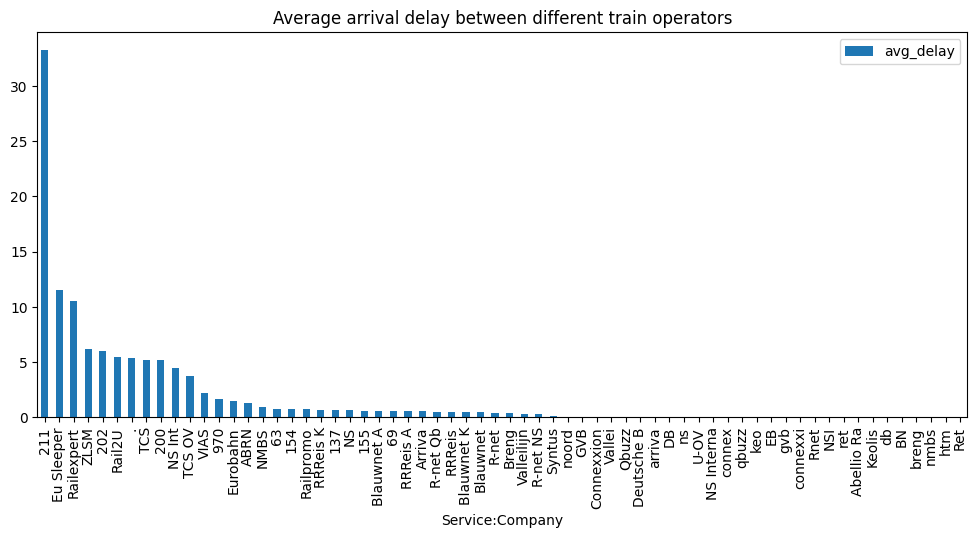

In [41]:
# VII. Compare the average arrival delay between different train operators (Service:Company) on a bar plot. Sort them appropriately.

avg_delays = db.sql("""
SELECT "Service:Company", ROUND(AVG(COALESCE("Stop:Arrival delay", 0)), 2) AS avg_delay
FROM services
GROUP BY "Service:Company"
ORDER BY avg_delay DESC
""").df()

avg_delays.plot.bar(
    x="Service:Company",
    y="avg_delay",
    title="Average arrival delay between different train operators",
    figsize=(12, 5),
)


<Axes: title={'center': 'Number of disrupted services over time'}, xlabel='year'>

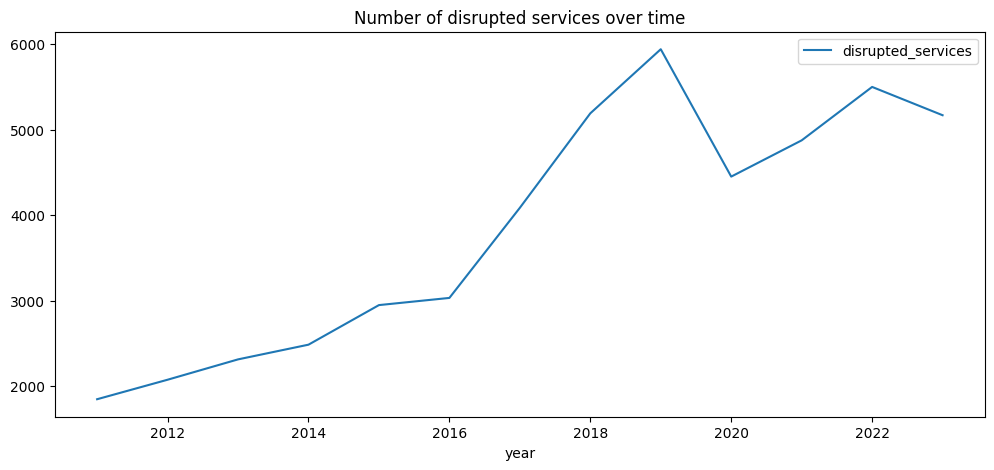

In [30]:
# VIII. How many services were disrupted in different years? Make a line plot.

disrupted_services = db.sql("""
SELECT EXTRACT(YEAR FROM "start_time") as year, COUNT(*) as disrupted_services
FROM postgres_db.disruptions
GROUP BY year
ORDER BY year
""").df()

disrupted_services.plot.line(
    x="year",
    y="disrupted_services",
    title="Number of disrupted services over time",
    figsize=(12, 5),
)


<Axes: title={'center': 'Fraction of cancelled services over time'}, xlabel='year'>

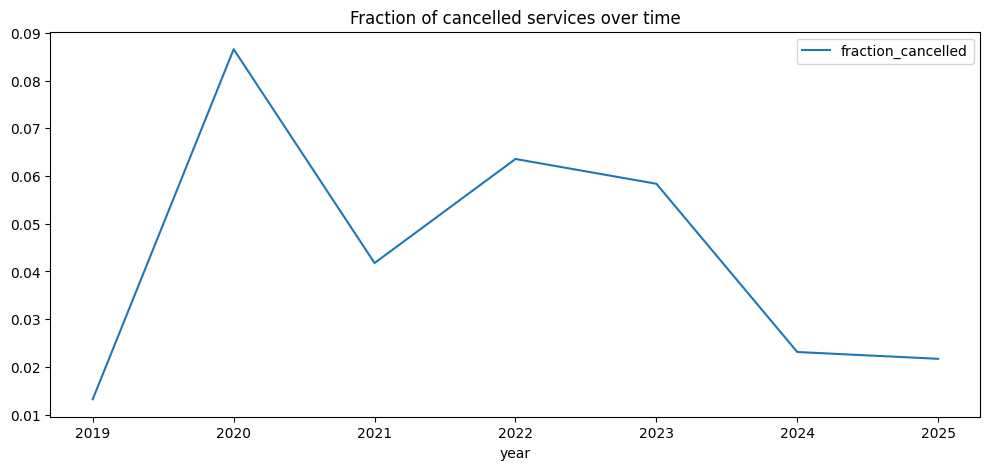

In [39]:
# IX. What fraction of all services were cancelled (Service:Completely cancelled) in different years? Make a line plot.

cancelled_services = db.sql("""
SELECT EXTRACT(YEAR FROM "Service:Date") as year,
COUNT(*) FILTER (WHERE cancelled) / COUNT(*) as fraction_cancelled
FROM (
    SELECT "Service:RDT-ID", "Service:Date",
    bool_or("Service:Completely cancelled") as cancelled
    FROM services
    GROUP BY "Service:RDT-ID", "Service:Date"
)
GROUP BY year
ORDER BY year
""").df()

cancelled_services.plot.line(
    x="year",
    y="fraction_cancelled",
    title="Fraction of cancelled services over time",
    figsize=(12, 5),
)

### Section 8.

In [17]:
db.sql("""
CREATE TABLE IF NOT EXISTS station_connections AS
WITH station_pairs AS (
    SELECT
        "Service:RDT-ID",
        "Stop:Station code",
        LEAD("Stop:Station code") OVER (
            PARTITION BY "Service:RDT-ID"
            ORDER BY "Stop:Departure time"
        ) AS next_station_code
    FROM services
)
SELECT DISTINCT
    "Service:RDT-ID",
    "Stop:Station code" as start_station_code,
    next_station_code as end_station_code,
    dl.distance
FROM station_pairs
JOIN distances_long dl ON dl."Station" = "Stop:Station code"
AND dl.other_station = next_station_code
""")

db.sql("""
SELECT *
FROM station_connections
LIMIT 50
""")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌────────────────┬────────────────────┬──────────────────┬──────────┐
│ Service:RDT-ID │ start_station_code │ end_station_code │ distance │
│     int64      │      varchar       │     varchar      │  int64   │
├────────────────┼────────────────────┼──────────────────┼──────────┤
│        5757897 │ ZL                 │ ASN              │       78 │
│        5758311 │ KMA                │ WM               │        2 │
│        5758963 │ FWD                │ ZH               │       28 │
│        5760993 │ APN                │ LDL              │       14 │
│        5762813 │ KTR                │ OP               │        4 │
│        5768123 │ UTLN               │ HTN              │        4 │
│        5769085 │ MRN                │ VNDW             │       14 │
│        5770386 │ RAT                │ NVD              │       14 │
│        5773425 │ SGL                │ VK               │        3 │
│        5774049 │ MES                │ SGL              │        4 │
│           ·    │  

In [19]:
# What is the largest distance between a pair of stations?

db.sql("""
SELECT start_station_code, end_station_code, distance
FROM station_connections
ORDER BY distance DESC
LIMIT 1
""")


┌────────────────────┬──────────────────┬──────────┐
│ start_station_code │ end_station_code │ distance │
│      varchar       │     varchar      │  int64   │
├────────────────────┼──────────────────┼──────────┤
│ VS                 │ STV              │      421 │
└────────────────────┴──────────────────┴──────────┘

In [21]:
# Plot a histogram of inter-station distances run by trains.

df = db.sql("""
SELECT distance
FROM station_connections
""").df()


<Axes: title={'center': 'Histogram of inter-station distances run by trains'}, ylabel='Frequency'>

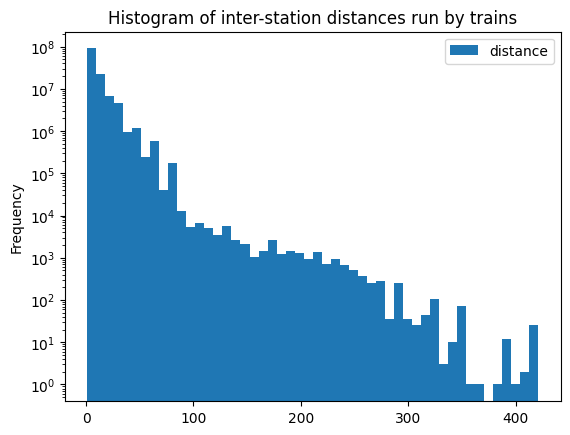

In [25]:
df.plot.hist(
    bins=50,
    title="Histogram of inter-station distances run by trains",
    logy=True,
)